In [2]:
# MM811 - Programming Assignment
# Question 1

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Source: GeeksforGeeks - MNIST Dataset
# https://www.geeksforgeeks.org/machine-learning/mnist-dataset/ (Accessed 10/17/26)

def load_mnist(batch_size=5, train=True):
    transform = transforms.ToTensor()
    dataset = datasets.MNIST(
        root="./data",
        train=train,
        download=True,
        transform=transform
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=train)

def visualize_samples(dataloader, num_samples=5):
    images, labels = next(iter(dataloader))

    plt.figure(figsize=(15, 3))
    for i in range(num_samples):
        plt.subplot(1, num_samples, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.title(f"Label: {labels[i].item()}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

train_loader = load_mnist(batch_size=64, train=True)
test_loader = load_mnist(batch_size=64, train=False)
# visualize_samples(train_loader)

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 478kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.20MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.40MB/s]


In [5]:
# Retrieve one batch from the training DataLoader. Initially for testing
# images, labels = next(iter(train_loader))

# Print the dimensions
# print("Images shape:", images.shape)
# print("Labels shape:", labels.shape)

In [6]:
# Source: PyTorch: Build the Neural Network
# https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html
# Medium: Implementation on MNIST in PyTorch - Deepesh Deepak
# https://medium.com/@deepeshdeepakdd2/lenet-5-implementation-on-mnist-in-pytorch-c6f2ee306e37
# (Accessed 10/17/25)
class LeNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Feature extraction
        self.feature = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, stride=1, padding=2),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),

            nn.Conv2d(6, 16, kernel_size=5, stride=1),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2)
        )

        # Classification
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120),
            nn.Tanh(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10)
        )

    def forward(self, x):
        x = self.feature(x)
        x = self.classifier(x)
        return x


In [7]:
# model = LeNet()

# images, labels = next(iter(train_loader))

# outputs = model(images)

# print("Input shape:", images.shape)
# print("Output shape:", outputs.shape)

In [8]:
# Training the LeNet model
# Source PyTorch - Optimizing Model Parameters
# https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html
# (Accessed 10/17/25)

# Set up the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = LeNet().to(device)

learning_rate = 1e-3
epochs = 5

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)


Using device: cuda


In [11]:
# Source PyTorch - Optimizing Model Parameters
# https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html
# (Accessed 10/17/25)

def train_loop(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)

    model.train()

    for batch, (X, y) in enumerate(dataloader):
        # Move images and labels to the GPU
        X, y = X.to(device), y.to(device)

        # Make predictions
        pred = model(X)

        # Calculate the loss
        loss = loss_fn(pred, y)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Display training progress
        if batch % 100 == 0:
            loss_value = loss.item()
            current = min((batch + 1) * len(X), size)
            print(f"Loss: {loss_value:.4f} [{current}/{size}]")

In [12]:

# Source PyTorch - Optimizing Model Parameters
# https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html
# (Accessed 10/17/25)

def test_loop(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    model.eval()

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)

            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size

    print(f"Test Accuracy: {(100 * correct):.2f}%")
    print(f"Average Test Loss: {test_loss:.4f}")

In [13]:
# Train and evaluate LeNet for 5 epochs

for epoch in range(epochs):
    print(f"Epoch {epoch + 1}/{epochs}")
    print("-------------------------------")

    train_loop(train_loader, model, loss_fn, optimizer)
    test_loop(test_loader, model, loss_fn)

print("Training Complete!")

Epoch 1/5
-------------------------------
Loss: 2.3007 [64/60000]
Loss: 0.5840 [6464/60000]
Loss: 0.3870 [12864/60000]
Loss: 0.1708 [19264/60000]
Loss: 0.0950 [25664/60000]
Loss: 0.2499 [32064/60000]
Loss: 0.3351 [38464/60000]
Loss: 0.3413 [44864/60000]
Loss: 0.1054 [51264/60000]
Loss: 0.0376 [57664/60000]
Test Accuracy: 95.94%
Average Test Loss: 0.1307
Epoch 2/5
-------------------------------
Loss: 0.1299 [64/60000]
Loss: 0.0214 [6464/60000]
Loss: 0.1027 [12864/60000]
Loss: 0.0725 [19264/60000]
Loss: 0.1527 [25664/60000]
Loss: 0.1222 [32064/60000]
Loss: 0.0360 [38464/60000]
Loss: 0.1051 [44864/60000]
Loss: 0.2002 [51264/60000]
Loss: 0.0915 [57664/60000]
Test Accuracy: 97.65%
Average Test Loss: 0.0791
Epoch 3/5
-------------------------------
Loss: 0.0196 [64/60000]
Loss: 0.0240 [6464/60000]
Loss: 0.0467 [12864/60000]
Loss: 0.0261 [19264/60000]
Loss: 0.0110 [25664/60000]
Loss: 0.0328 [32064/60000]
Loss: 0.0411 [38464/60000]
Loss: 0.0396 [44864/60000]
Loss: 0.2532 [51264/60000]
Loss: 0

In [14]:
# Source PyTorch - Save and Load the Model
# https://docs.pytorch.org/tutorials/beginner/basics/saveloadrun_tutorial.html
# (Accessed 10/17/25)
torch.save(model.state_dict(), "lenet_mnist.pth")

print("LeNet model weights saved")

LeNet model weights saved


In [16]:
drive.mount('/content/drive')

torch.save(
    model.state_dict(),
    '/content/drive/MyDrive/M811_Assignment/lenet_mnist.pth'
)

print("Model saved successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved successfully!


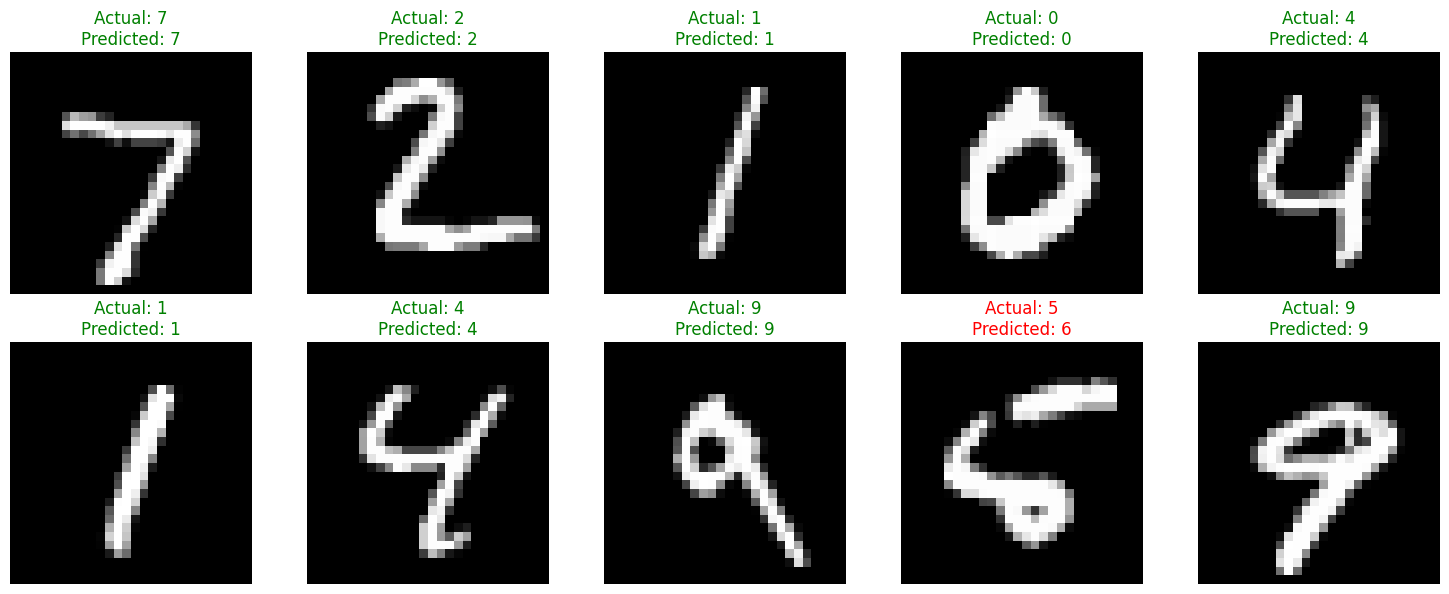

In [17]:
# Testing the trained model
# Source PyTorch - Datasets & DataLoaders
# https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html
# (Accessed 10/17/25)

model.eval()
images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = model(images.to(device))
    predictions = outputs.argmax(dim=1).cpu()

plt.figure(figsize=(15, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")

    actual = labels[i].item()
    predicted = predictions[i].item()

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color
    )
    plt.axis("off")

plt.tight_layout()
plt.savefig(
    "/content/drive/MyDrive/M811_Assignment/lenet_predictions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

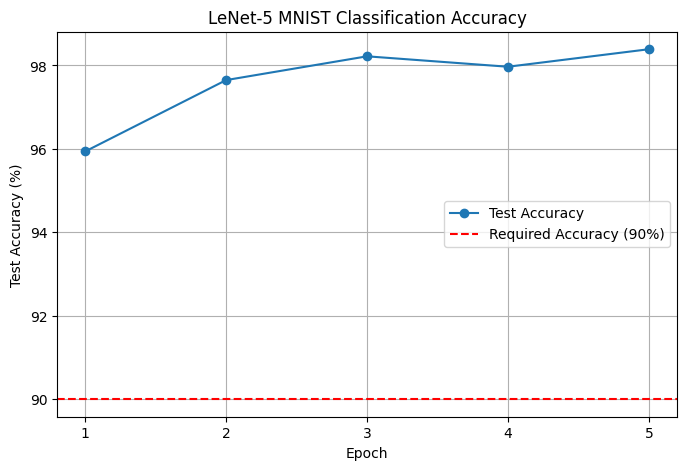

In [18]:
# Source Matplotlib.pyplot.plot
# https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html
# (Accessed 10/17/25)

epochs_list = [1, 2, 3, 4, 5]
test_accuracy = [95.94, 97.65, 98.22, 97.97, 98.39]

plt.figure(figsize=(8, 5))
plt.plot(epochs_list, test_accuracy, marker="o", label="Test Accuracy")

plt.axhline(y=90, linestyle="--", color="red", label="Required Accuracy (90%)")

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("LeNet-5 MNIST Classification Accuracy")
plt.xticks(epochs_list)
plt.legend()
plt.grid(True)

plt.savefig(
    "/content/drive/MyDrive/M811_Assignment/Task1_Classification/lenet_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

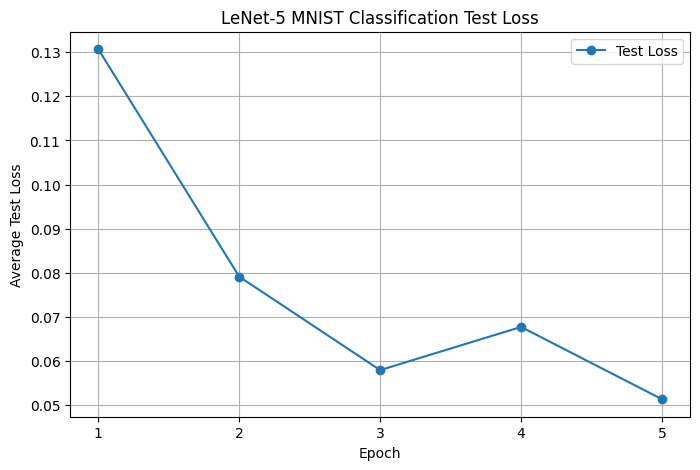

In [19]:

epochs_list = [1, 2, 3, 4, 5]
test_loss = [0.1307, 0.0791, 0.0579, 0.0677, 0.0513]

plt.figure(figsize=(8, 5))
plt.plot(epochs_list, test_loss, marker="o", label="Test Loss")

plt.xlabel("Epoch")
plt.ylabel("Average Test Loss")
plt.title("LeNet-5 MNIST Classification Test Loss")
plt.xticks(epochs_list)
plt.legend()
plt.grid(True)

plt.savefig(
    "/content/drive/MyDrive/M811_Assignment/Task1_Classification/lenet_test_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()